In [1]:
import numpy as np
import h5py
import os
import sys

from matplotlib import pyplot as plt
from tqdm import tqdm

import torch
import sparse

In [ ]:
import numba

@numba.njit()
def sparse_to_sparse(coords, values, num_prongs, num_features, shape_scale):
    DIMS = 4
    max_items = values.shape[0] + num_prongs
    
    output_coordinates = np.zeros((max_items, DIMS - 1), dtype=np.int64)
    output_values = np.zeros((max_items, num_features), dtype=np.float32)
    
    index_mapping = dict()
    num_unique_indices = 0

    for i in range(values.shape[0]): 
        v = values[i]
        if v == 0:
            continue

        b = coords[i, 0]
        c = coords[i, 1]
        y = coords[i, 2]
        x = coords[i, 3]
        
        if num_features == 3 and c == 1:
            y = 399 - y 

        flat_index = shape_scale[0] * b + shape_scale[1] * y + shape_scale[2] * x

        if flat_index not in index_mapping:
            output_index = num_unique_indices
            index_mapping[flat_index] = num_unique_indices
            num_unique_indices += 1
        else:
            output_index = index_mapping[flat_index]

        output_coordinates[output_index][0] = b
        output_coordinates[output_index][1] = y
        output_coordinates[output_index][2] = x

        output_values[output_index][c] = v

    non_zero_planes = set(output_coordinates[:num_unique_indices, 0])
    all_planes = set(np.arange(num_prongs, dtype=np.int64))
    missing_planes = all_planes.difference(non_zero_planes)

    for i in missing_planes:
        output_coordinates[num_unique_indices, 0] = i
        num_unique_indices += 1

    output_coordinates = output_coordinates[:num_unique_indices]
    output_values = output_values[:num_unique_indices]

    sorting_indices = np.argsort((output_coordinates * shape_scale).sum(1))
    output_coordinates = np.ascontiguousarray(output_coordinates[sorting_indices])
    output_values = np.ascontiguousarray(output_values[sorting_indices])
    
    return output_coordinates, output_values

def compress_first_index(indices, values, shape):
    assert np.all(np.diff(indices[:, 0]) >= 0)

    starts = np.searchsorted(indices[:, 0], np.arange(shape[0]))
    ends = np.concatenate((starts[1:], [indices.shape[0]]))

    return np.stack([starts, ends]).T

In [3]:
# @numba.njit()
# def all_sparse_to_sparse(event_compressed_index, cvnmap_index, cvnmap_value, cvnmap_shape, shape_scale):
#     all_event_coordinates = []
#     all_event_values = []

#     for i in range(event_compressed_index.shape[0]):
#         lower, upper = event_compressed_index[i]
#         num_prongs = 1
#         num_features = cvnmap_shape[2]

#         event_coordinates = cvnmap_index[lower:upper, 1:]
#         event_values = cvnmap_value[lower:upper]
#         event_coordinates, event_values = sparse_to_sparse(event_coordinates, event_values, num_prongs, num_features, shape_scale)

#         all_event_coordinates.append(event_coordinates)
#         all_event_values.append(event_values)
        
#         if i % 100000 == 0:
#             print(i)
        
#     event_lengths = np.array([0] + list(map(len, all_event_coordinates)))
#     event_compressed_index = np.stack((np.cumsum(event_lengths)[:-1], np.cumsum(event_lengths)[1:]), axis=1)

#     # all_event_values = np.concatenate(all_event_values)
#     # all_event_coordinates = np.concatenate(all_event_coordinates) 
    
#     return all_event_values, all_event_coordinates

In [ ]:
# TRAIN = 0.8
# TEST = 0.2

# assert(TRAIN + TEST == 1)

In [ ]:
RENAME_PRONG_TARGET = False
ENERGY_LIMIT = None


# file = h5py.File("/baldig/physicsprojects2/dune_prong_reco/data/data/dune/new_data/preprocessed_data_dune_train.h5", 'r')
# OUTPUT = "training"

# PATH = "/baldig/physicsprojects2/dune_prong_reco/data/data/dune/cut_data/preprocessed_data_dune_vertices_train.h5"
# OUTPUT = "training_filter"

# PATH = "/baldig/physicsprojects2/dune_prong_reco/data/data/dune/cut_data/preprocessed_data_dune_vertices_test.h5"
# OUTPUT = "testing_filter"
PATH = "./output/preprocessed_pixel_maps_test.h5"
OUTPUT = "output"

# file = h5py.File("/baldig/physicsprojects2/dune_prong_reco/data/data/dune/new_data/preprocessed_data_dune_eval.h5", 'r')
# OUTPUT = "testing"

In [ ]:
# RENAME_PRONG_TARGET = True

# ENERGY_LIMIT = None
# ENERGY_LIMIT = 1.5

# file = h5py.File("./data/nova/raw/preprocessed_data_slicelid_prongid.h5", 'r')
# OUTPUT = "training"

# # file = h5py.File("./data/nova/raw/preprocessed_data_slicelid_prongid_eval.h5", 'r')
# # OUTPUT = "testing"

# file = h5py.File("./data/nova/raw/preprocessed_prod5_slicelid_transformer_eval.h5", 'r')
# OUTPUT = "production"

# PATH = "./data/nova_alt/raw/preprocessed_nova_prod5.1_FHC_calibdown_train.h5"
# OUTPUT = "calibdown"

# # file = h5py.File("./data/nova/raw/preprocessed_prod5_slicelid_transformer_vertices.h5", 'r')
# # OUTPUT = "interpretation"

# # file = h5py.File("./data/nova/raw/preprocessed_pixel_maps_rhc.h5", 'r')
# # OUTPUT = "training_rhc"

#PATH = "/mnt/ironwolf_14t2/users/ayankelevich/preprocessed_nova_miniprod6_1_hits_truth.h5"
#OUTPUT = "training_prod6"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1.h5"
#OUTPUT = "training_prod6_1"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1_1_1.h5"
#OUTPUT = "training_prod6_1_1"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1_1_2.h5"
#OUTPUT = "training_prod6_1_2"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1_2_1.h5"
#OUTPUT = "training_prod6_1_3"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1_2_2.h5"
#OUTPUT = "training_prod6_1_4"

# PATH = "/mnt/ironwolf_20t/users/ayankelevich/preprocessed_nova_miniprod6_1_opal_2.h5"
# OUTPUT = "training_prod6opal"

# PATH = "/mnt/ironwolf_20t/users/ayankelevich/preprocessed_nova_miniprod6_1_opal_1_1.h5"
# OUTPUT = "training_prod6opal_1"

# PATH = "/mnt/ironwolf_20t/users/ayankelevich/preprocessed_nova_miniprod6_1_opal_1_2.h5"
# OUTPUT = "training_prod6opal_2"

In [ ]:
# RENAME_PRONG_TARGET = False

# ENERGY_LIMIT = None

# PATH = "preprocessed_data_dune_atmnu.test.h5"
# OUTPUT = "postprocessed_data_dune_atmnu.test.h5"

# PATH = "preprocessed_data_dune_atmnu.train.h5"
# OUTPUT = "postprocessed_data_dune_atmnu.train.h5"

In [67]:
# from statsmodels.distributions.empirical_distribution import ECDF
# from scipy import optimize, stats
# import seaborn as sb

# ecdf = ECDF(extra.ravel())
# YY = extra.ravel()
# # YY = np.log(extra.ravel() + 1)
# XX = np.linspace(YY.min(), YY.max(), 1024)
# dist = stats.rv_histogram(np.histogram(
#     YY, 
#     bins=256, 
#     range=(YY.min() - 1e-6, YY.max() + 1e-6)
# ))
# weight = 1.0 / dist.pdf(YY)

In [68]:
# sb.set_theme("notebook", "whitegrid", font_scale=1.5)
# plt.figure(figsize=(12, 6))
# plt.plot(XX, dist.pdf(XX), linewidth=3);
# plt.xlabel("Energy")
# plt.ylabel("Density")

In [69]:
# sb.set_theme("notebook", "whitegrid", font_scale=1.5)
# plt.figure(figsize=(12, 6))
# plt.plot(np.linspace(YY.min(), 5, 1024), dist.pdf(np.linspace(YY.min(), 5, 1024)), linewidth=3);
# plt.xlabel("Energy")
# plt.ylabel("Density")

In [70]:
# sb.set_theme("notebook", "whitegrid", font_scale=1.5)
# plt.figure(figsize=(12, 6))
# plt.plot(XX, dist.pdf(XX), linewidth=3);
# plt.xlabel("$Log$ Energy")
# plt.ylabel("Density")

In [71]:
# plt.figure(figsize=(9, 4))
# plt.hist(
#     [
#         extra[current_target == 0].ravel(), 
#         extra[current_target == 1].ravel(), 
#     ],
#     bins=128, 
#     range=(0, 5), 
#     histtype="step",
#     linewidth=1,
#     label=[
#         "$\\nu_\\mu$",
#         "$\\nu_e$"
#     ]
# );
# plt.xlabel("GeV");
# plt.legend();
# plt.savefig("energy_dist.png")

In [6]:
file = h5py.File(PATH, 'r')

num_events, num_prongs, *_ = file["png_cvnmap_shape"][:]

data = file["input_png3d"][:] if "input_png3d" in file else np.zeros((num_events, 24, num_prongs), dtype=np.float32)
mask = png_cvnmap_pad_mask = file['input_png3d_pad_mask'][:] if "input_png3d_pad_mask" in file else np.zeros((num_events, num_prongs), dtype=bool)
extra = file["input_slice"][:] if "input_slice" in file else np.zeros(num_events, dtype=np.float32)

try:
    nu_energy = file["mc.nuEnergy"][:]
    lep_energy = file["mc.LepEnergy"][:]
except KeyError:
    pass

target = file["mc.inter"][:]
prong_targets = file["mc.png_label_split_photons"][:]

data = data.astype(np.float32)
data = data.transpose((0, 2, 1))
data = np.ascontiguousarray(data)

extra = extra.reshape(data.shape[0], -1).astype(np.float32)

unique_targets = np.unique(target)
target_map = {key: value for key, value in map(reversed, enumerate(unique_targets))}
target = np.fromiter((target_map[t] for t in target), dtype=np.int64, count=len(target))

current_target = np.zeros_like(target)
current_target[(target > 3) & (target <= 7)] = 1
current_target[target == 8] = 2
current_target[target == 9] = 3

if RENAME_PRONG_TARGET:
    prong_targets[prong_targets == 9] = 8
    
if not mask.any():
    mask = prong_targets >= 0

In [7]:
del current_target

In [8]:
print("\n".join(file.keys()))

cvn0neutrons
cvn0pions
cvn0pizeros
cvn0protons
cvn1neutrons
cvn1pions
cvn1pizeros
cvn1protons
cvn2neutrons
cvn2pions
cvn2pizeros
cvn2protons
cvnNneutrons
cvnNpions
cvnNpizeros
cvnNprotons
cvnmap_index
cvnmap_shape
cvnmap_value
cvnnc
cvnnue
cvnnumu
cvnnutau
input_png3d
input_png3d_pad_mask
input_slice
isNonFlux
mc.inter
mc.png_label
mc.png_label_split_photons
mc.png_mother
png_ShwTrk
png_cvnmap_index
png_cvnmap_shape
png_cvnmap_value
png_trueE
png_trueP
tpc_id
trueE
trueP
trueVertex


In [9]:
list(zip(range(9), np.bincount(prong_targets[prong_targets >= 0]) / (prong_targets >= 0).sum()))

[(0, 0.16326179886342407),
 (1, 0.11015340060836915),
 (2, 0.34590060421135144),
 (3, 0.0017756573618820748),
 (4, 0.14363199819939584),
 (5, 0.2178642328943991),
 (6, 0.009235303150669212),
 (7, 0.008177004710509087)]

In [10]:
png_cvnmap_index = file["png_cvnmap_index"][:]
png_cvnmap_value = file["png_cvnmap_value"][:]
png_cvnmap_shape = file["png_cvnmap_shape"][:]

In [11]:
png_cvnmap_index[:,0]-=png_cvnmap_index[0][0]

In [12]:
cvnmap_index = file["cvnmap_index"][:]
cvnmap_value = file["cvnmap_value"][:]
cvnmap_shape = file["cvnmap_shape"][:]

In [13]:
cvnmap_index[:,0]-=cvnmap_index[0][0]

In [14]:
cvnmap_index[-1]

array([483943,      2,    166,    183], dtype=int32)

In [15]:
cvnmap_shape

array([483944,      3,    350,    350])

In [14]:
HAS_VERTEX = "vertex_index" in file
if HAS_VERTEX:
    vertex_index = file["vertex_index"][:]
    scaled_dir = file["scaled_dir"][:]

In [10]:
import seaborn as sb
import cmasher as cmr
sb.set_theme("poster", "white", rc={"text.usetex": False}, font_scale=1.2)

PRONG_TARGET_MAP = {
    0: "$e$",
    1: "$\\mu$",
    2: "$p$",
    3: "$\\gamma_n$",
    4: "$\\pi^{\\pm}$",
    5: "$\\gamma_{\\pi}$",
    6: "$\\gamma$",
    7: "other",
}
EVENT_TARGET_MAP = ["$\\nu_\\mu$", "$\\nu_e$", "Neutral", "None"]

In [15]:
if HAS_VERTEX:
    II = 50
    II = 21

    BASE_SIZE = 4

    prong_image = np.zeros(png_cvnmap_shape[1:])
    prong_mask = png_cvnmap_index[:, 0] == II
    prong_image[png_cvnmap_index[prong_mask, 1], png_cvnmap_index[prong_mask, 2]] = png_cvnmap_value[prong_mask]
    prong_image = prong_image

    event_image = np.zeros(cvnmap_shape[1:])
    event_mask = cvnmap_index[:, 0] == II
    event_image[cvnmap_index[event_mask, 1]] = cvnmap_value[event_mask]

    num_prongs = png_cvnmap_index[prong_mask, 1].max() + 1
    prong_image = prong_image.reshape(10, 2, 100, 80)
    event_image = event_image.reshape(2, 100, 80)

    fig, axes = plt.subplots(nrows=2, ncols=num_prongs + 1, figsize=(BASE_SIZE * (num_prongs + 1) * 0.95, BASE_SIZE * 2))
    SS = 24
    pz, px, py = vertex_index[II, 0]
    XLIM = slice(0, SS * 2)
    YLIM = slice(80 // 2 - SS, 80 // 2 + SS)
    CMAP = cmr.eclipse

    for i, row in enumerate(axes):
        for j, ax in enumerate(row):
            title = f"{'Top' if i == 0 else 'Side'} View"

            if j == 0:
                if i == 0:
                    YLIM = slice(px - SS, px + SS)
                else:
                    YLIM = slice(py - SS, py + SS)

                pax = ax.imshow(event_image[i, XLIM, YLIM], cmap=CMAP)
                if i == 0:
                    ax.set_title(f"Event Label: {EVENT_TARGET_MAP[current_target[II]]}", pad=10, color='r')
                ax.set_ylabel(title)
                ax.set_xticks([])
                ax.set_yticks([])             
            else:
                pax = ax.imshow(prong_image[j - 1, i, XLIM, YLIM], cmap=CMAP)
                if i == 0:
                    ax.set_title(f"Prong Label: {PRONG_TARGET_MAP[prong_targets[II, j - 1]]}", pad=10)
                ax.set_xticks([])
                ax.set_yticks([])

    plt.tight_layout()
    plt.savefig("./example_event_nova.png", dpi=300, bbox_inches="tight")

In [14]:
# II = 50
# PII = 0

# FF = data[II]
# PP = np.zeros(png_cvnmap_shape[1:])

# MM = png_cvnmap_index[:, 0] == II
# PP[png_cvnmap_index[MM, 1], png_cvnmap_index[MM, 2]] = png_cvnmap_value[MM]

# VZ, VX, VY = vertex_index[II, PII]
# DX, DY, DZ = scaled_dir[II, PII]

# fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 8))
# ax1.imshow(PP[PII][:8000].reshape(100, 80), cmap='viridis')
# ax1.scatter(VX, VZ, c='r', marker='o')
# ax1.quiver(VX, VZ, DX, -DZ / 2, color="r", scale=2)

# ax2.imshow(PP[PII][8000:].reshape(100, 80), cmap='viridis')
# ax2.scatter(VY, VZ, c='r', marker='o')
# ax2.quiver(VY, VZ, DY, -DZ / 2, color="r", scale=2)

# plt.tight_layout()
# plt.savefig("example_vertex.png", bbox_inches="tight")
# print(prong_targets[II, PII])

In [16]:
extra_index = np.zeros(cvnmap_index.shape[0], dtype=cvnmap_index.dtype)
cvnmap_index = np.insert(cvnmap_index, 1, extra_index, axis=1)
cvnmap_shape = np.insert(cvnmap_shape, 1, 1)

In [84]:
if RENAME_PRONG_TARGET:
    cvnmap_index = np.ascontiguousarray(cvnmap_index.T)
    cvnmap = sparse.COO(cvnmap_index, cvnmap_value, tuple(map(int, cvnmap_shape)))
    del cvnmap_index, cvnmap_value
    cvnmap = cvnmap.reshape((*cvnmap.shape[:2], 2, 100, 80)) 

    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)
    del cvnmap

In [85]:
if RENAME_PRONG_TARGET:
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap_index.T)
    png_cvnmap = sparse.COO(png_cvnmap_index, png_cvnmap_value, tuple(map(int, png_cvnmap_shape)))
    png_cvnmap = png_cvnmap.reshape((*png_cvnmap.shape[:2], 2, 100, 80))
    del png_cvnmap_index, png_cvnmap_value

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)
    del png_cvnmap

In [27]:
# cvnmap_dense = cvnmap.todense()
# cvnmap_dense = cvnmap_dense[:, 0]

# np.savez(
#     "./nova_event_images_prod51_small.npz", 
#     images=cvnmap_dense[:1024*32], 
#     targets=current_target[:1024*32]
# )

In [ ]:
if ENERGY_LIMIT:
    energy_mask = extra.ravel() < ENERGY_LIMIT
    
    cvnmap = cvnmap[energy_mask]
    png_cvnmap = png_cvnmap[energy_mask]
    
    extra = extra[energy_mask]
    data = data[energy_mask]
    mask = mask[energy_mask]

    target = target[energy_mask]
    prong_targets = prong_targets[energy_mask]

    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)

In [14]:
(extra.ravel() < 1.5).mean()

1.0

In [19]:
if os.path.exists(PATH.replace(".h5", ".select.npy")):
    select_mask = np.load(PATH.replace(".h5", ".select.npy")) > 0.5
    select_mask = np.append(select_mask, [False])
    
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap_index.T)
    cvnmap_index = np.ascontiguousarray(cvnmap_index.T)

    png_cvnmap = sparse.COO(png_cvnmap_index, png_cvnmap_value, tuple(map(int, png_cvnmap_shape)))
    cvnmap = sparse.COO(cvnmap_index, cvnmap_value, tuple(map(int, cvnmap_shape)))
    
    cvnmap = cvnmap[select_mask]
    png_cvnmap = png_cvnmap[select_mask]
    
    extra = extra[select_mask]
    data = data[select_mask]
    mask = mask[select_mask]
    
    target = target[select_mask]
    prong_targets = prong_targets[select_mask]
    
    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)

In [17]:
event_compressed_index = compress_first_index(cvnmap_index, cvnmap_value, cvnmap_shape)

In [18]:
prong_compressed_index = compress_first_index(png_cvnmap_index, png_cvnmap_value, png_cvnmap_shape)

In [19]:
image_size = cvnmap_shape[-2:]
shape_scale = np.ascontiguousarray(np.cumprod((*cvnmap_shape[-2:], 1)[::-1])[::-1])

In [20]:
image_size = png_cvnmap_shape[-2:]
shape_scale = np.ascontiguousarray(np.cumprod((*png_cvnmap_shape[-2:], 1)[::-1])[::-1])

In [21]:
from joblib import Parallel, delayed

In [22]:
def extract_event(i):
    lower, upper = event_compressed_index[i]
    num_prongs = 1
    num_features = cvnmap_shape[2]

    event_coordinates = cvnmap_index[lower:upper, 1:]
    event_values = cvnmap_value[lower:upper]
    return sparse_to_sparse(event_coordinates, event_values, num_prongs, num_features, shape_scale)

In [23]:
event_results = Parallel(n_jobs=32, verbose=1)(delayed(extract_event)(i) for i in range(len(event_compressed_index)))
all_event_coordinates = [result[0] for result in event_results]
all_event_values = [result[1] for result in event_results]

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done 136 tasks      | elapsed:   11.2s
[Parallel(n_jobs=32)]: Done 1345 tasks      | elapsed:   11.9s
[Parallel(n_jobs=32)]: Done 27569 tasks      | elapsed:   14.3s
[Parallel(n_jobs=32)]: Done 85169 tasks      | elapsed:   18.4s
[Parallel(n_jobs=32)]: Done 162880 tasks      | elapsed:   22.5s
[Parallel(n_jobs=32)]: Done 329280 tasks      | elapsed:   27.7s
[Parallel(n_jobs=32)]: Done 482080 tasks      | elapsed:   32.5s
[Parallel(n_jobs=32)]: Done 483944 out of 483944 | elapsed:   32.6s finished


In [24]:
del cvnmap_value, cvnmap_index, event_results

In [36]:
# all_event_values, all_event_coordinates = all_sparse_to_sparse(event_compressed_index, cvnmap_index, cvnmap_value, cvnmap_shape, shape_scale)

In [37]:
# all_event_coordinates = []
# all_event_values = []

# for i in tqdm(range(event_compressed_index.shape[0])):
#     lower, upper = event_compressed_index[i]
#     num_prongs = 1
#     num_features = cvnmap_shape[2]
    
#     event_coordinates = cvnmap_index[lower:upper, 1:]
#     event_values = cvnmap_value[lower:upper]
#     event_coordinates, event_values = sparse_to_sparse(event_coordinates, event_values, num_prongs, num_features, shape_scale)
    
#     all_event_coordinates.append(event_coordinates)
#     all_event_values.append(event_values)

In [25]:
event_lengths = np.array([0] + list(map(len, all_event_coordinates)))
event_compressed_index = np.stack((np.cumsum(event_lengths)[:-1], np.cumsum(event_lengths)[1:]), axis=1)

all_event_values = np.concatenate(all_event_values)
all_event_coordinates = np.concatenate(all_event_coordinates)

In [26]:
del event_lengths

In [27]:
def extract_prong(i):
    lower, upper = prong_compressed_index[i]
    
    num_prongs = max(mask[i].sum(), 1)
    num_features = png_cvnmap_shape[2]
    
    prong_coordinates = png_cvnmap_index[lower:upper, 1:]
    prong_values = png_cvnmap_value[lower:upper]
    return sparse_to_sparse(prong_coordinates, prong_values, num_prongs, num_features, shape_scale)

In [28]:
prong_results = Parallel(n_jobs=32, verbose=1)(delayed(extract_prong)(i) for i in range(len(prong_compressed_index)))
all_prong_coordinates = [result[0] for result in prong_results]
all_prong_values = [result[1] for result in prong_results]

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done 136 tasks      | elapsed:    4.3s
[Parallel(n_jobs=32)]: Done 1754 tasks      | elapsed:    4.9s
[Parallel(n_jobs=32)]: Done 29728 tasks      | elapsed:    8.8s
[Parallel(n_jobs=32)]: Done 128544 tasks      | elapsed:   11.3s
[Parallel(n_jobs=32)]: Done 269344 tasks      | elapsed:   14.9s
[Parallel(n_jobs=32)]: Done 435744 tasks      | elapsed:   19.3s
[Parallel(n_jobs=32)]: Done 483944 out of 483944 | elapsed:   20.6s finished


In [29]:
del png_cvnmap_value, png_cvnmap_index, prong_results

In [29]:
dir()

['ENERGY_LIMIT',
 'In',
 'OUTPUT',
 'Out',
 'PATH',
 'Parallel',
 'RENAME_PRONG_TARGET',
 'TEST',
 'TRAIN',
 '_',
 '_13',
 '_14',
 '_8',
 '__',
 '___',
 '__builtin__',
 '__builtins__',
 '__doc__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 '_dh',
 '_i',
 '_i1',
 '_i10',
 '_i11',
 '_i12',
 '_i13',
 '_i14',
 '_i15',
 '_i16',
 '_i17',
 '_i18',
 '_i19',
 '_i2',
 '_i20',
 '_i21',
 '_i22',
 '_i23',
 '_i24',
 '_i25',
 '_i26',
 '_i27',
 '_i28',
 '_i29',
 '_i3',
 '_i4',
 '_i5',
 '_i6',
 '_i7',
 '_i8',
 '_i9',
 '_ih',
 '_ii',
 '_iii',
 '_oh',
 'all_event_coordinates',
 'all_event_values',
 'all_prong_coordinates',
 'all_prong_values',
 'compress_first_index',
 'cvnmap_shape',
 'data',
 'delayed',
 'event_compressed_index',
 'exit',
 'extra',
 'extra_index',
 'extract_event',
 'extract_prong',
 'file',
 'get_ipython',
 'h5py',
 'image_size',
 'mask',
 'np',
 'num_events',
 'num_prongs',
 'numba',
 'open',
 'os',
 'plt',
 'png_cvnmap_pad_mask',
 'png_cvnmap_shape',
 'prong_compresse

In [38]:
# all_prong_coordinates = []
# all_prong_values = []

# for i in tqdm(range(prong_compressed_index.shape[0])):
#     lower, upper = prong_compressed_index[i]
    
#     num_prongs = max(mask[i].sum(), 1)
#     num_features = png_cvnmap_shape[2]
    
#     prong_coordinates = png_cvnmap_index[lower:upper, 1:]
#     prong_values = png_cvnmap_value[lower:upper]
#     prong_coordinates, prong_values = sparse_to_sparse(prong_coordinates, prong_values, num_prongs, num_features, shape_scale)
    
#     all_prong_coordinates.append(prong_coordinates)
#     all_prong_values.append(prong_values)

In [30]:
prong_lengths = np.array([0] + list(map(len, all_prong_coordinates)))
prong_compressed_index = np.stack((np.cumsum(prong_lengths)[:-1], np.cumsum(prong_lengths)[1:]), axis=1)

all_prong_values = np.concatenate(all_prong_values)
all_prong_coordinates = np.concatenate(all_prong_coordinates)

In [31]:
del prong_lengths

In [32]:
all_event_coordinates = all_event_coordinates.astype(np.int32)

In [33]:
all_prong_coordinates = all_prong_coordinates.astype(np.int32)

In [34]:
num_events, max_prongs, *full_pixels_shape = png_cvnmap_shape

In [41]:
raw_event_compressed_index = compress_first_index(cvnmap_index, cvnmap_value, cvnmap_shape)

NameError: name 'cvnmap_index' is not defined

In [42]:
raw_prong_compressed_index = compress_first_index(png_cvnmap_index, png_cvnmap_value, png_cvnmap_shape)

NameError: name 'png_cvnmap_index' is not defined

In [23]:
from MinkowskiEngine import SparseTensor

/home/ayankelevich/.local/lib/python3.10/site-packages/MinkowskiEngine/__init__.py:36: UserWarning: The environment variable `OMP_NUM_THREADS` not set. MinkowskiEngine will automatically set `OMP_NUM_THREADS=16`. If you want to set `OMP_NUM_THREADS` manually, please export it on the command line before running a python script. e.g. `export OMP_NUM_THREADS=12; python your_program.py`. It is recommended to set it below 24.
  warnings.warn(


In [43]:
IDX = 123122
V = all_prong_values[prong_compressed_index[IDX, 0]:prong_compressed_index[IDX, 1]]
C = all_prong_coordinates[prong_compressed_index[IDX, 0]:prong_compressed_index[IDX, 1]]
D = SparseTensor(torch.from_numpy(V), torch.from_numpy(C).int()).dense(torch.Size(png_cvnmap_shape[1:]))[0].numpy()
print(np.unique(C[:, 0]).shape[0] - max(mask[IDX].sum(), 1))

0


/lv_scratch/scratch/dune_prong/environment/lib/python3.10/site-packages/MinkowskiEngine/__init__.py:36: UserWarning: The environment variable `OMP_NUM_THREADS` not set. MinkowskiEngine will automatically set `OMP_NUM_THREADS=16`. If you want to set `OMP_NUM_THREADS` manually, please export it on the command line before running a python script. e.g. `export OMP_NUM_THREADS=12; python your_program.py`. It is recommended to set it below 24.
  warnings.warn(


In [24]:
IDX = 123122
V = all_event_values[event_compressed_index[IDX, 0]:event_compressed_index[IDX, 1]]
C = all_event_coordinates[event_compressed_index[IDX, 0]:event_compressed_index[IDX, 1]]
D = SparseTensor(torch.from_numpy(V), torch.from_numpy(C).int()).dense(torch.Size(cvnmap_shape[1:]))[0].numpy()
print(np.unique(C[:, 0]).shape[0] - max(mask[IDX].sum(), 1))

-3


In [45]:
CC = png_cvnmap_index[raw_prong_compressed_index[IDX, 0]:raw_prong_compressed_index[IDX, 1]]
VV = png_cvnmap_value[raw_prong_compressed_index[IDX, 0]:raw_prong_compressed_index[IDX, 1]]
DD = sparse.COO(CC.T[1:], VV, tuple(map(int, png_cvnmap_shape[1:]))).todense()
# DD[:, 1] = DD[:, 1, ::-1]

In [28]:
from MinkowskiEngine import SparseTensor

IDX = 60
V = all_event_values[event_compressed_index[IDX, 0]:event_compressed_index[IDX, 1]]
C = all_event_coordinates[event_compressed_index[IDX, 0]:event_compressed_index[IDX, 1]]
D = SparseTensor(torch.from_numpy(V), torch.from_numpy(C)).dense(torch.Size((1, 3, 400, 280)))[0].numpy()

CC = cvnmap_index[raw_event_compressed_index[IDX, 0]:raw_event_compressed_index[IDX, 1]]
VV = cvnmap_value[raw_event_compressed_index[IDX, 0]:raw_event_compressed_index[IDX, 1]]
DD = sparse.COO(CC.T[1:], VV, tuple(map(int, cvnmap_shape[1:]))).todense()
DD[:, 1] = DD[:, 1, ::-1]

In [29]:
DD.shape

(1, 2, 100, 80)

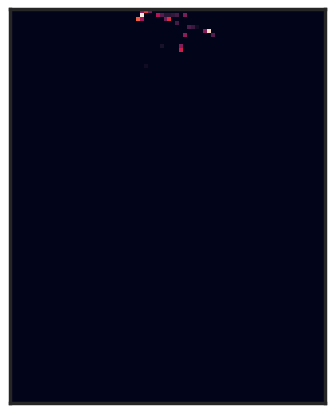

In [30]:
plt.imshow(DD[0, 0])
plt.grid(False)
plt.xticks([], [])
plt.yticks([], [])
plt.tight_layout()
plt.savefig("dune_plane.png", bbox_inches="tight")

In [49]:
#OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse.h5"
#if ENERGY_LIMIT:
#    OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse_{ENERGY_LIMIT}_gev.h5"
#    
#print(OUTPUT_FILE)

./data/nova_alt/calibdown_prong_pixels_minkowski_sparse.h5


In [50]:
# OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse.h5"
# if ENERGY_LIMIT:
#     OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse_{ENERGY_LIMIT}_gev.h5"
    
# print(OUTPUT_FILE)

In [35]:
OUTPUT_FILE = f"./{OUTPUT}"
if ENERGY_LIMIT:
    OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse_{ENERGY_LIMIT}_gev.h5"
    
print(OUTPUT_FILE)

./postprocessed_data_dune_atmnu.train.h5


In [36]:
with h5py.File(OUTPUT_FILE, 'w') as output_file:
    output_file.create_dataset("features", data=data)
    output_file.create_dataset("extra", data=extra)

In [37]:
with h5py.File(OUTPUT_FILE, 'a') as output_file:
    output_file.create_dataset("event_target", data=target)
    output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates)
    output_file.create_dataset("event_pixels_values", data=all_event_values)
    output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
    output_file.create_dataset("event_compressed_index", data=event_compressed_index)

In [38]:
del all_event_coordinates,all_event_values,event_compressed_index

In [39]:
with h5py.File(OUTPUT_FILE, 'a') as output_file:
    output_file.create_dataset("prong_target", data=prong_targets)
    output_file.create_dataset("prong_mask", data=mask)
    
    output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates)
    output_file.create_dataset("prong_pixels_values", data=all_prong_values)
    output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
    output_file.create_dataset("prong_compressed_index", data=prong_compressed_index)

    output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [40]:
del all_prong_coordinates,all_prong_values,prong_compressed_index

In [27]:
def sizeof_fmt(num, suffix='B'):
    ''' by Fred Cirera,  https://stackoverflow.com/a/1094933/1870254, modified'''
    for unit in ['','Ki','Mi','Gi','Ti','Pi','Ei','Zi']:
        if abs(num) < 1024.0:
            return "%3.1f %s%s" % (num, unit, suffix)
        num /= 1024.0
    return "%.1f %s%s" % (num, 'Yi', suffix)

for name, size in sorted(((name, sys.getsizeof(value)) for name, value in list(
                          locals().items())), key= lambda x: -x[1])[:10]:
    print("{:>30}: {:>8}".format(name, sizeof_fmt(size)))

                           _16: 21.4 GiB
         all_event_coordinates: 11.8 GiB
              all_event_values:  7.9 GiB
                   extra_index:  4.3 GiB
        event_compressed_index: 117.9 MiB
                          mask: 73.7 MiB
           png_cvnmap_pad_mask: 73.7 MiB
                 prong_targets: 73.7 MiB
                 event_results: 59.7 MiB
                 event_lengths: 59.0 MiB


In [107]:
with h5py.File("./data/nova/training_prong_pixels_minkowski_sparse.h5", 'r') as output_file:
    dataset = {
        key: value[:]
        for key, value in output_file.items()
    }

FileNotFoundError: [Errno 2] Unable to open file (unable to open file: name = './data/nova/training_prong_pixels_minkowski_sparse.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [51]:
baseline = {
    key: file[key][select_mask] 
    for key in file.keys() 
    if "cvn" in key
    and "_index" not in key
    and "_shape" not in key
    and "_value" not in key
}

np.savez(OUTPUT_FILE.replace("h5", "baseline.npz"), **baseline)

In [ ]:
with h5py.File(f"./data/dune/{OUTPUT}_prong_pixels_minkowski_sparse_new.h5", 'w') as output_file:
    output_file.create_dataset("features", data=data)
    output_file.create_dataset("extra", data=extra)
    output_file.create_dataset("event_target", data=target)
    output_file.create_dataset("prong_target", data=prong_targets)
    output_file.create_dataset("prong_mask", data=mask)
    
    output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates)
    output_file.create_dataset("prong_pixels_values", data=all_prong_values)
    output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
    output_file.create_dataset("prong_compressed_index", data=prong_compressed_index)
    
    output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates)
    output_file.create_dataset("event_pixels_values", data=all_event_values)
    output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
    output_file.create_dataset("event_compressed_index", data=event_compressed_index)
        
    output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [30]:
SMALL_SIZE = 100_000
final_prong_compressed = prong_compressed_index[SMALL_SIZE, 0]
final_event_compressed = event_compressed_index[SMALL_SIZE, 0]

In [31]:
with h5py.File(f"./data/dune/small_{OUTPUT}_prong_pixels_minkowski_sparse_new.h5", 'w') as output_file:
    output_file.create_dataset("features", data=data[:SMALL_SIZE])
    output_file.create_dataset("prong_mask", data=mask[:SMALL_SIZE])
    output_file.create_dataset("extra", data=extra[:SMALL_SIZE])
    output_file.create_dataset("event_target", data=target[:SMALL_SIZE])
    output_file.create_dataset("prong_target", data=prong_targets[:SMALL_SIZE])

    output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates[:final_prong_compressed])
    output_file.create_dataset("prong_pixels_values", data=all_prong_values[:final_prong_compressed])
    output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
    output_file.create_dataset("prong_compressed_index", data=prong_compressed_index[:SMALL_SIZE])
    
    output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates[:final_event_compressed])
    output_file.create_dataset("event_pixels_values", data=all_event_values[:final_event_compressed])
    output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
    output_file.create_dataset("event_compressed_index", data=event_compressed_index[:SMALL_SIZE])
        
    output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [60]:
SMALL_SIZE = 10_000
final_prong_compressed = prong_compressed_index[SMALL_SIZE, 0]
final_event_compressed = event_compressed_index[SMALL_SIZE, 0]

In [61]:
with h5py.File(f"./data/dune/tiny_{OUTPUT}_prong_pixels_minkowski_sparse_new.h5", 'w') as output_file:
    output_file.create_dataset("features", data=data[:SMALL_SIZE])
    output_file.create_dataset("prong_mask", data=mask[:SMALL_SIZE])
    output_file.create_dataset("extra", data=extra[:SMALL_SIZE])
    output_file.create_dataset("event_target", data=target[:SMALL_SIZE])
    output_file.create_dataset("prong_target", data=prong_targets[:SMALL_SIZE])

    output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates[:final_prong_compressed])
    output_file.create_dataset("prong_pixels_values", data=all_prong_values[:final_prong_compressed])
    output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
    output_file.create_dataset("prong_compressed_index", data=prong_compressed_index[:SMALL_SIZE])
    
    output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates[:final_event_compressed])
    output_file.create_dataset("event_pixels_values", data=all_event_values[:final_event_compressed])
    output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
    output_file.create_dataset("event_compressed_index", data=event_compressed_index[:SMALL_SIZE])
        
    output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [107]:
import matplotlib
import seaborn as sb

TARGET_MAP = {
    -1: "event",
    0: "electron",
    1: "muon",
    2: "proton",
    3: "photon from neutron",
    4: "charged pion",
    5: "photon from neutral pion",
    6: "other photon",
    7: "other",
    8: "none"
}

sb.set_theme(context="talk", style="white", palette="deep", font_scale=1.5)

In [95]:
with h5py.File(f"./data/dune/small_{OUTPUT}_prong_pixels_no_subtract_full_targets.h5", 'r') as file:
    cleaned_data = file["data"][:]
    cleaned_mask = file["mask"][:]
    cleaned_extra = file["extra"][:]
    cleaned_target = file["target"][:]
    cleaned_prong_targets = file["prong_target"][:]
    prong_pixels_indices = file["prong_pixels_indices"][:]
    prong_pixels_values = file["prong_pixels_values"][:]
    prong_pixels_shape = file["prong_pixels_shape"][:]
    full_pixels_shape = file["full_pixels_shape"][:]

In [96]:
prong_pixels = sparse.COO(prong_pixels_indices, prong_pixels_values, tuple(map(int, prong_pixels_shape)))

In [110]:
IDX = 60
mask = cleaned_mask[IDX]
num_prongs = mask.sum()
images = prong_pixels[IDX].todense()[:num_prongs]
images = images.reshape(-1, *full_pixels_shape).copy()
images = np.log(images + 1)
images[:, 1] = images[:, 1, ::-1]

prong_targets = cleaned_prong_targets[IDX, :num_prongs].copy()
# prong_targets[0] = cleaned_target[IDX]

In [111]:
images[0, 0].min()

0.0

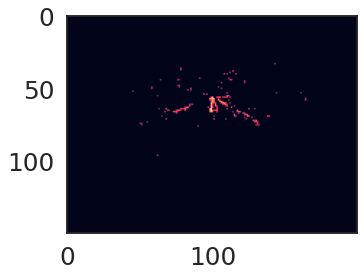

In [137]:
plt.imshow(images[0, 0, :150, 40:240])

In [130]:
images.shape

(8, 3, 400, 280)

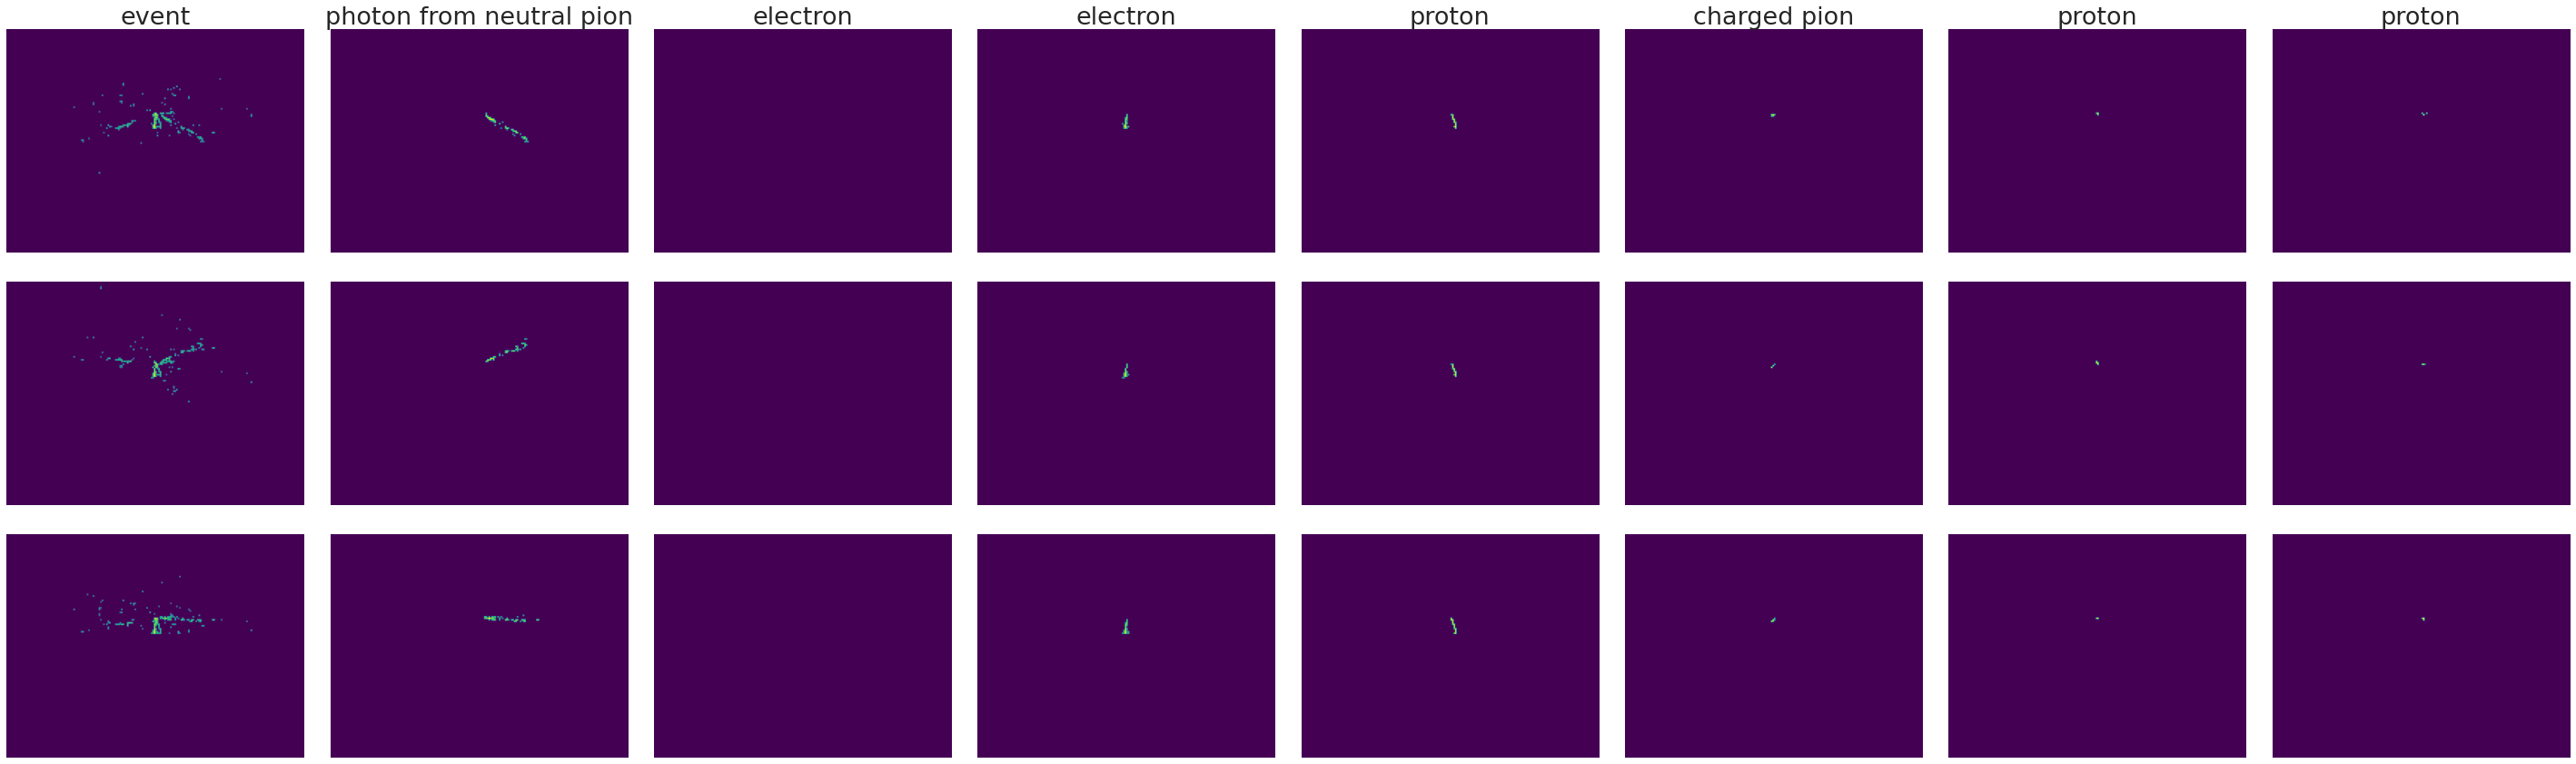

In [146]:
INDEX =60
BASE = 5

fig, axes = plt.subplots(nrows=3, ncols=num_prongs, figsize=(num_prongs * BASE, 2.5 * BASE))
for i, row in enumerate(axes):
    for j, ax in enumerate(row):
        if i == 0:
            ax.set_title(TARGET_MAP[prong_targets[j]])
            
        ax.imshow(images[j, i, :150, 40:240], cmap="viridis")
        ax.set_axis_off()
        ax.xaxis.set_major_locator(matplotlib.ticker.NullLocator())
        ax.yaxis.set_major_locator(matplotlib.ticker.NullLocator())
        
plt.tight_layout()
plt.savefig("event.png", dpi=300, bbox_inches="tight")

In [25]:
extra

array([[1.7918227],
       [3.28834  ],
       [1.1697736],
       ...,
       [2.2605214],
       [1.5480424],
       [2.449605 ]], dtype=float32)

In [1]:
cvnmap[INDEX]

NameError: name 'cvnmap' is not defined